# Taller RL — aportación de Hugo: test común y estado enriquecido

**Grupo:** Javier Chulvi Bernad · Hugo Vinuesa Busson · Higinio Paterna Ortiz

Los notebooks de Higinio (Q-learning) y Javi (SARSA) ajustan cada algoritmo en los cuatro mercados. El propio
informe señala dos limitaciones que este notebook aborda:

1. **No hay un test común.** Q-learning y SARSA se evaluaron sobre lotes de series distintos, así que las
   diferencias entre algoritmos no pueden atribuirse solo al método. Aquí los dos se entrenan con **las mismas 5
   semillas** y se evalúan sobre **las mismas 200 series de test por mercado** (semillas 700.000-700.003, no usadas
   antes), con el mismo criterio de convergencia y una prueba por pares (Wilcoxon) serie a serie.
2. **El estado es pobre.** Solo contiene la tendencia de 6 pasos y la posición, sin información sobre la distancia
   al nivel medio, que es justo lo que necesita una estrategia de reversión a la media. Añadimos una variable:
   la **distancia del precio a su media móvil de 20 pasos** (8 intervalos), y repetimos el test común.

Se reutilizan **literalmente** el entorno y los generadores del enunciado, la discretización de la tendencia
(14 × 2 × 3) y los **hiperparámetros elegidos por validación** en los notebooks de Higinio y Javi (tabla 1 del
informe). No se vuelven a ajustar para el estado enriquecido, así que su resultado es conservador.

## 1. Entorno y generadores (copiados del enunciado)

In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np


class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1
        self.action_space = spaces.Discrete(3)
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5
        self.position = 0
        self.initial_balance = 1000.0
        self.balance = self.initial_balance
        self.cash = self.initial_balance
        self.shares = 0.0
        return self._get_obs(), {}

    def _get_obs(self):
        window = self.prices[self.current_step - 5: self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]
        reward = 0.0
        cost_rate = 0.001
        if action == 2 and self.position == 0:
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate
        elif action == 0 and self.position == 1:
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash
        terminated = self.current_step >= self.max_steps
        return self._get_obs(), reward, terminated, False, {"balance": self.balance}


def generar_precios(n_steps=1000):
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = np.random.normal(0, 0.1, n_steps)
    retornos = drift + ciclo + ruido
    return 100 * np.cumprod(1 + retornos)


def generar_precios_browniano(n_steps=1000, start_price=100.0, mu=0.0001, sigma=0.02):
    retornos = np.random.normal((mu - 0.5 * sigma**2), sigma, n_steps)
    return start_price * np.cumprod(np.exp(retornos))


def generar_precios_reversion_media(n_steps=1000, start_price=100.0, mean_price=100.0, kappa=0.05, volatility=0.02):
    precios = np.zeros(n_steps)
    precios[0] = start_price
    for t in range(1, n_steps):
        delta = kappa * (mean_price - precios[t-1]) + np.random.normal(0, volatility * mean_price)
        precios[t] = max(precios[t-1] + delta, 0.1)
    return precios


def generar_precios_regimenes(n_steps=1000, start_price=100.0):
    estado = 0
    retornos = []
    for _ in range(n_steps):
        if np.random.rand() < 0.02:
            estado = 1 - estado
        retornos.append(np.random.normal(0.001, 0.01) if estado == 0 else np.random.normal(-0.0015, 0.025))
    return np.maximum(start_price * np.cumprod(1 + np.array(retornos)), 0.1)


GENERADORES = {
    "Tendencia + ciclo": generar_precios,
    "Browniano": generar_precios_browniano,
    "Reversión a la media": generar_precios_reversion_media,
    "Cambios de régimen": generar_precios_regimenes,
}

## 2. Estados: original y enriquecido

- **Original**: `(tendencia de 6 pasos discretizada en 14 intervalos, posición)` → tabla 14 × 2 × 3.
- **Enriquecido**: añade `distancia = precio / media móvil de 20 pasos − 1`, discretizada en 8 intervalos
  (±1 %, ±3 %, ±6 %) → tabla 14 × 8 × 2 × 3. Se calcula a partir de los precios ya observados (no mira el futuro).

In [2]:
# ---------- Estados ----------
TREND_BINS = np.array([-0.10, -0.05, -0.03, -0.02, -0.01, -0.005, 0.0,
                       0.005, 0.01, 0.02, 0.03, 0.05, 0.10], dtype=np.float32)   # los de Higinio y Javi
DIST_BINS = np.array([-0.06, -0.03, -0.01, 0.0, 0.01, 0.03, 0.06])               # distancia a la media de 20 pasos
MA_WINDOW = 20


def estado_original(obs, env):
    return int(np.digitize(obs[0], TREND_BINS)), int(obs[1])


def estado_enriquecido(obs, env):
    """Añade la distancia del precio actual a su media móvil de 20 pasos (o la historia disponible)."""
    t = env.current_step
    w = env.prices[max(0, t - MA_WINDOW + 1): t + 1]
    dist = env.prices[t] / np.mean(w) - 1.0
    return int(np.digitize(obs[0], TREND_BINS)), int(np.digitize(dist, DIST_BINS)), int(obs[1])


SHAPES = {"original": (len(TREND_BINS) + 1, 2, 3),
          "enriquecido": (len(TREND_BINS) + 1, len(DIST_BINS) + 1, 2, 3)}
ESTADOS = {"original": estado_original, "enriquecido": estado_enriquecido}

## 3. Hiperparámetros elegidos por el grupo (sin cambios)

In [3]:
# ---------- Configuraciones elegidas por Higinio (Q) y Javi (SARSA), tabla 1 del informe ----------
#            alpha, gamma, eps0, eps_min, N (episodios hasta eps_min), episodios
CONFIG = {
    "Q-learning": {
        "Tendencia + ciclo":    dict(alpha=0.05, gamma=0.99, eps0=0.5, eps_min=0.01, N=750, episodes=1000),
        "Browniano":            dict(alpha=0.05, gamma=0.95, eps0=0.5, eps_min=0.01, N=250, episodes=1000),
        "Reversión a la media": dict(alpha=0.05, gamma=0.99, eps0=0.5, eps_min=0.01, N=250, episodes=1000),
        "Cambios de régimen":   dict(alpha=0.05, gamma=0.99, eps0=1.0, eps_min=0.01, N=500, episodes=1000),
    },
    "SARSA": {
        "Tendencia + ciclo":    dict(alpha=0.05, gamma=0.99, eps0=1.0, eps_min=0.01, N=800, episodes=2000),
        "Browniano":            dict(alpha=0.05, gamma=0.99, eps0=1.0, eps_min=0.01, N=250, episodes=1000),
        "Reversión a la media": dict(alpha=0.05, gamma=0.99, eps0=1.0, eps_min=0.05, N=800, episodes=2000),
        "Cambios de régimen":   dict(alpha=0.10, gamma=0.99, eps0=1.0, eps_min=0.01, N=800, episodes=1000),
    },
}

## 4. Entrenamiento, evaluación y convergencia

`entrenar` implementa los dos algoritmos con el mismo esquema que los notebooks del grupo: serie nueva en cada
episodio, Q se conserva, ε-greedy con decaimiento por episodio. **Q-learning** actualiza con $\max_{a'} Q(s',a')$ y
después elige $a'$; **SARSA** elige $a'$ antes y actualiza con $Q(s',a')$. La evaluación es voraz (ε = 0) y no
modifica Q. Para la convergencia se aplica **a ambos** el criterio de Higinio (bloques de 50 episodios, cambios ≤ 0,5 pp
hasta el final, al menos 3 bloques estables).

In [4]:
# ---------- Entrenamiento, evaluación y convergencia ----------
def greedy(q, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(3))
    v = q[s]
    best = np.flatnonzero(v == v.max())
    return int(best[0]) if len(best) == 1 else int(rng.choice(best))


def entrenar(algoritmo, mercado, estado="original", seed=1, n_steps=500):
    """Q-learning (objetivo con max Q') o SARSA (objetivo con Q(s',a') de la acción elegida).
    Mismo esquema que los notebooks del grupo: serie nueva por episodio, Q se conserva, eps decae por episodio."""
    c = CONFIG[algoritmo][mercado]
    decay = (c["eps_min"] / c["eps0"]) ** (1.0 / c["N"])
    gen, phi = GENERADORES[mercado], ESTADOS[estado]
    np.random.seed(seed)
    rng = np.random.default_rng(seed)
    q = np.zeros(SHAPES[estado], dtype=np.float32)
    eps, returns = c["eps0"], []
    for _ in range(c["episodes"]):
        env = SimpleTradingEnv(gen(n_steps=n_steps))
        obs, _ = env.reset()
        s = phi(obs, env)
        a = greedy(q, s, eps, rng)
        done = False
        while not done:
            obs, r, done, _, info = env.step(a)
            s2 = phi(obs, env)
            if algoritmo == "Q-learning":       # actualiza con max Q(s',·) y después elige a' (como Higinio)
                target = r if done else r + c["gamma"] * q[s2].max()
                q[(*s, a)] += c["alpha"] * (target - q[(*s, a)])
                a2 = None if done else greedy(q, s2, eps, rng)
            else:                               # elige a' antes y la usa en el objetivo (como Javi)
                a2 = None if done else greedy(q, s2, eps, rng)
                target = r if done else r + c["gamma"] * q[(*s2, a2)]
                q[(*s, a)] += c["alpha"] * (target - q[(*s, a)])
            s, a = s2, a2
        returns.append(info["balance"] / env.initial_balance - 1.0)
        eps = max(c["eps_min"], eps * decay)
    return q, np.asarray(returns)


def series_test(mercado, n=200, seed=700_000, n_steps=500):
    st = np.random.get_state()
    np.random.seed(seed)
    try:
        return [GENERADORES[mercado](n_steps=n_steps) for _ in range(n)]
    finally:
        np.random.set_state(st)


def evaluar(series, politica, seed=0):
    """politica(obs, env, rng) -> acción. Devuelve retornos y nº de operaciones por serie."""
    rets, trades = np.zeros(len(series)), np.zeros(len(series))
    for i, p in enumerate(series):
        env = SimpleTradingEnv(p)
        obs, _ = env.reset()
        rng = np.random.default_rng(seed + i)
        done, n = False, 0
        while not done:
            pos = env.position
            obs, _, done, _, info = env.step(politica(obs, env, rng))
            n += int(env.position != pos)
        rets[i], trades[i] = info["balance"] / env.initial_balance - 1.0, n
    return rets, trades


def politica_q(q, estado):
    phi = ESTADOS[estado]
    return lambda obs, env, rng: greedy(q, phi(obs, env), 0.0, rng)


def aleatorio(obs, env, rng):
    return int(rng.integers(3))


def buy_hold(obs, env, rng):
    return 2 if env.position == 0 else 1


def convergencia(returns, block=50, thr=0.005, stable=3):
    """Criterio de Higinio (bloques de 50 episodios, cambios <= 0,5 pp hasta el final), aplicado a ambos."""
    nb = len(returns) // block
    m = returns[:nb * block].reshape(nb, block).mean(1)
    ch = np.abs(np.diff(m))
    for i in range(len(ch) - stable + 1):
        if np.all(ch[i:] <= thr):
            return (i + 2) * block
    return None

## 5. Experimento

4 mercados × 2 algoritmos × 2 estados × 5 semillas = 80 agentes, evaluados sobre las mismas 200 series de test
por mercado. Los baselines (aleatorio y buy & hold) se evalúan sobre esas mismas series.
**Tarda unos 25 minutos** en un portátil (≈ 15 s por agente).

In [5]:
import itertools, time
import pandas as pd
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt

SEEDS = [1, 2, 3, 4, 5]
MERCADOS = list(GENERADORES)
TEST = {m: series_test(m, n=200, seed=700_000 + i) for i, m in enumerate(MERCADOS)}

R, t0 = {}, time.time()
for m, a, e, s in itertools.product(MERCADOS, ["Q-learning", "SARSA"], ["original", "enriquecido"], SEEDS):
    t = time.time()
    q, tr = entrenar(a, m, e, seed=s)
    secs = time.time() - t
    ret, trades = evaluar(TEST[m], politica_q(q, e), seed=900_000)
    R[(m, a, e, s)] = dict(ret=ret, trades=trades, train_returns=tr, secs=secs, q=q)
B = {m: {"Aleatorio": evaluar(TEST[m], aleatorio, seed=900_000),
         "Buy & hold": evaluar(TEST[m], buy_hold, seed=900_000)} for m in MERCADOS}
print(f"{len(R)} agentes entrenados y evaluados en {(time.time() - t0) / 60:.1f} min")

80 agentes entrenados y evaluados en 29.3 min


## 6. Resultados en el test común

In [6]:
M = lambda m, a, e: np.vstack([R[(m, a, e, s)]["ret"] for s in SEEDS])      # semillas x series
T = lambda m, a, e: np.vstack([R[(m, a, e, s)]["trades"] for s in SEEDS])

rows = []
for m in MERCADOS:
    for a in ["Q-learning", "SARSA"]:
        for e in ["original", "enriquecido"]:
            X, Tr = M(m, a, e), T(m, a, e)
            conv = [convergencia(R[(m, a, e, s)]["train_returns"]) for s in SEEDS]
            cv = [c for c in conv if c is not None]
            rows.append({"Mercado": m, "Agente": f"{a} · {e}", "Media (%)": 100 * X.mean(),
                         "Mediana (%)": 100 * np.median(X), "Desv. (%)": 100 * X.std(),
                         "Operaciones/serie": Tr.mean(), "Agentes que operan": f"{(Tr.sum(1) > 0).sum()}/5",
                         "Convergencia (ep., semillas)": f"{int(np.mean(cv))} ({len(cv)}/5)" if cv else "no (0/5)",
                         "s/agente": np.mean([R[(m, a, e, s)]["secs"] for s in SEEDS])})
    for b in ["Aleatorio", "Buy & hold"]:
        r, t = B[m][b]
        rows.append({"Mercado": m, "Agente": b, "Media (%)": 100 * r.mean(), "Mediana (%)": 100 * np.median(r),
                     "Desv. (%)": 100 * r.std(), "Operaciones/serie": t.mean()})
tabla = pd.DataFrame(rows).set_index(["Mercado", "Agente"])
tabla.style.format(precision=2, na_rep="")

### Comparaciones por pares

Para cada serie de test se promedia el retorno de las 5 semillas y se comparan dos agentes serie a serie
(200 pares) con el test de rangos con signo de Wilcoxon. Al usar las **mismas series**, la diferencia sí puede
atribuirse al algoritmo o al estado.

In [7]:
def pares(x, y):
    d = x - y
    p = 1.0 if np.all(d == 0) else wilcoxon(x, y, zero_method="zsplit").pvalue
    return 100 * d.mean(), 100 * np.median(d), np.mean(d > 0), np.mean(d < 0), p

comp = []
for m in MERCADOS:
    q, s = M(m, "Q-learning", "original").mean(0), M(m, "SARSA", "original").mean(0)
    qe, se = M(m, "Q-learning", "enriquecido").mean(0), M(m, "SARSA", "enriquecido").mean(0)
    bh = B[m]["Buy & hold"][0]
    for nombre, x, y in [("Q-learning vs SARSA (estado original)", q, s),
                         ("Q-learning: enriquecido vs original", qe, q),
                         ("SARSA: enriquecido vs original", se, s),
                         ("Q-learning enriquecido vs buy & hold", qe, bh)]:
        dm, dmed, gana, pierde, p = pares(x, y)
        comp.append({"Mercado": m, "Comparación": nombre, "Dif. media (pp)": dm, "Dif. mediana (pp)": dmed,
                     "Gana (%)": 100 * gana, "Pierde (%)": 100 * pierde, "p Wilcoxon": p})
comparaciones = pd.DataFrame(comp).set_index(["Mercado", "Comparación"])
comparaciones.style.format({"Dif. media (pp)": "{:+.2f}", "Dif. mediana (pp)": "{:+.2f}",
                            "Gana (%)": "{:.0f}", "Pierde (%)": "{:.0f}", "p Wilcoxon": "{:.2g}"})

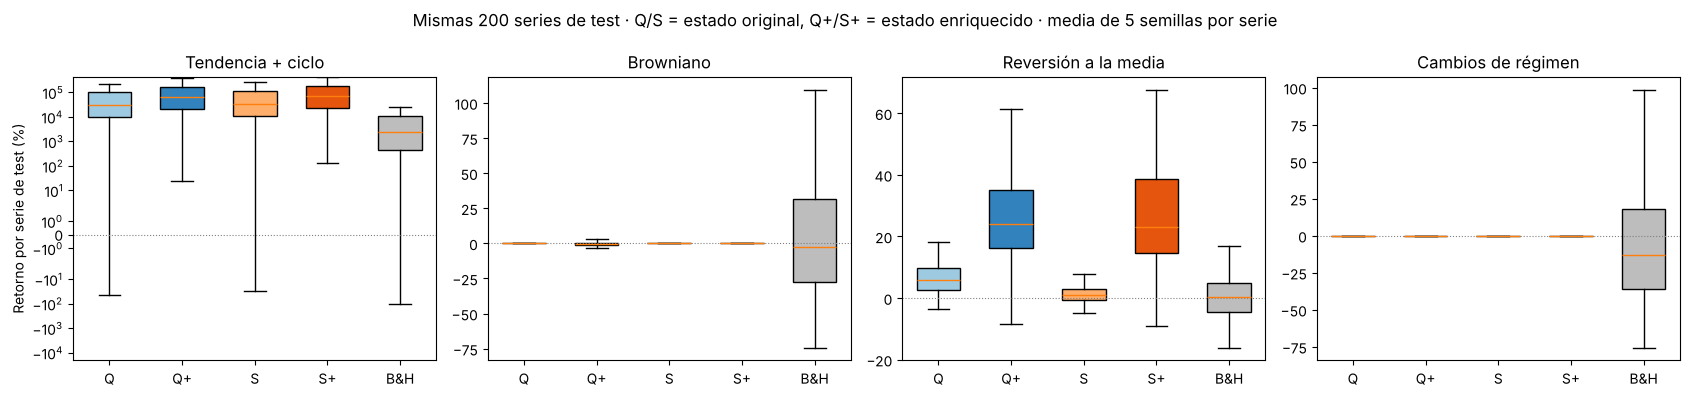

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
agentes = [("Q-learning", "original"), ("Q-learning", "enriquecido"), ("SARSA", "original"), ("SARSA", "enriquecido")]
colores = ["#9ecae1", "#3182bd", "#fdae6b", "#e6550d"]
for ax, m in zip(axes, MERCADOS):
    datos = [100 * M(m, a, e).mean(0) for a, e in agentes] + [100 * B[m]["Buy & hold"][0]]
    bp = ax.boxplot(datos, showfliers=False, patch_artist=True, widths=0.6)
    for patch, c in zip(bp["boxes"], colores + ["#bdbdbd"]):
        patch.set_facecolor(c)
    ax.set_xticks(range(1, 6), ["Q", "Q+", "S", "S+", "B&H"])
    ax.axhline(0, color="grey", lw=0.8, ls=":"); ax.set_title(m)
    if m == "Tendencia + ciclo": ax.set_yscale("symlog")
axes[0].set_ylabel("Retorno por serie de test (%)")
fig.suptitle("Mismas 200 series de test · Q/S = estado original, Q+/S+ = estado enriquecido · media de 5 semillas por serie")
plt.tight_layout(); plt.show()

### ¿Qué ha aprendido el agente enriquecido en reversión a la media?

Política voraz de Q-learning (semilla 1) cuando **no** tiene el activo: acción elegida según la tendencia de
6 pasos y la distancia a la media de 20 pasos. Si aprende la estrategia esperada, debería comprar cuando el precio
está por debajo de su media.

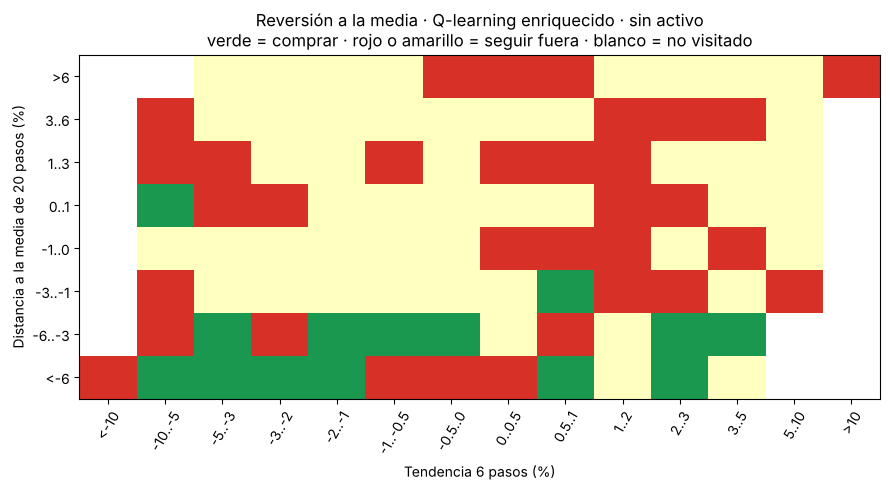

In [9]:
q = R[("Reversión a la media", "Q-learning", "enriquecido", 1)]["q"]
accion = q[:, :, 0, :].argmax(-1).astype(float)              # sin activo
accion[(q[:, :, 0, :] == 0).all(-1)] = np.nan                # estados nunca visitados
etq_t = ["<-10"] + [f"{a*100:g}..{b*100:g}" for a, b in zip(TREND_BINS[:-1], TREND_BINS[1:])] + [">10"]
etq_d = ["<-6"] + [f"{a*100:g}..{b*100:g}" for a, b in zip(DIST_BINS[:-1], DIST_BINS[1:])] + [">6"]
plt.figure(figsize=(9, 5))
plt.imshow(accion.T, cmap=plt.matplotlib.colors.ListedColormap(["#d73027", "#ffffbf", "#1a9850"]), vmin=0, vmax=2,
           aspect="auto", origin="lower")
plt.xticks(range(len(etq_t)), etq_t, rotation=60); plt.yticks(range(len(etq_d)), etq_d)
plt.xlabel("Tendencia 6 pasos (%)"); plt.ylabel("Distancia a la media de 20 pasos (%)")
plt.title("Reversión a la media · Q-learning enriquecido · sin activo\nverde = comprar · rojo o amarillo = seguir fuera · blanco = no visitado")
plt.tight_layout(); plt.show()

## 7. Conclusiones

**1. Con un test común, la diferencia entre algoritmos es pequeña y depende del mercado.** Sobre las mismas 200
series, con el estado original, Q-learning supera a SARSA en reversión a la media (+5,0 pp, gana en el 87 % de las
series, p < 10⁻²⁶), SARSA es algo mejor en tendencia (p = 0,035, con el doble de episodios por su configuración) y en
browniano y regímenes ambos se quedan casi siempre en efectivo. Con el estado enriquecido, Q-learning y SARSA
**empatan** en reversión (26,4 % frente a 26,4 %, p = 0,96).

**2. La representación del estado importa mucho más que el algoritmo.** Añadir la distancia a la media de 20 pasos,
sin reajustar ningún hiperparámetro:

- **Reversión a la media:** el retorno medio pasa de 6,1 % a 26,4 % en Q-learning y de 1,2 % a 26,4 % en SARSA; la
  mediana pasa de 0 % a ~24 %, y **los 5 agentes de cada algoritmo operan** (con el estado original 2 de 5 se quedaban
  en efectivo). Supera a buy & hold en el 96-98 % de las series. La política aprendida es la esperada: compra cuando el
  precio está más de un 3 % por debajo de su media y vende cuando está por encima.
- **Tendencia + ciclo:** la mediana se multiplica por ~2-3 y mejora en el 80 % de las series, con la mitad de
  operaciones. Las cifras absolutas siguen siendo extremas por cómo capitaliza este generador.
- **Browniano:** no hay nada que aprender (los incrementos son independientes). El estado enriquecido hace que Q-learning
  opere algo y pierda un poco (−0,4 pp, p < 10⁻⁴); es el comportamiento correcto quedarse fuera.
- **Cambios de régimen:** sin cambios relevantes; ambos preservan capital y superan a buy & hold en el 64 % de las
  series, pero no identifican los regímenes. Una media de 20 pasos es corta para regímenes que duran ~50 pasos.

**3. Convergencia con un criterio común.** Aplicando a ambos el criterio de bloques de Higinio, solo se detecta
estabilidad donde el agente acaba en efectivo (browniano y regímenes, ~700-900 episodios); en tendencia y reversión
ningún agente se estabiliza, lo que sugiere que más episodios o un α decreciente podrían mejorar aún el resultado.

**Límites:** hiperparámetros ajustados para el estado original (no reoptimizados), 5 semillas, mercados sintéticos.
El siguiente paso natural sería ajustar α/ε para el estado enriquecido y probar ventanas más largas en regímenes.